# Phase 3.1 — MLP: Time-Series Forecasting

**Research question:** Does a small feedforward PyTorch MLP improve SPY directional probability forecasts over the constant-prior, L2 logistic and XGBoost benchmarks?

Run **first**: `python -m quant_trading.phase3_mlp` from the project root. All training and walk-forward CV are implemented in `src/quant_trading/mlp_model.py` and `phase3_mlp.py` rather than duplicated in this notebook.

**No final test loaded.** Configuration: 17 tabular financial features, training-era 4-fold expanding CV, 3 predetermined seeds, 2 architectures × 2 weight-decay values = 48 fits, training-only StandardScaler, fixed 60 epochs, BCEWithLogitsLoss and AdamW.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

current_dir = Path.cwd().resolve()
for ROOT in (current_dir, *current_dir.parents):
    if (ROOT / "src" / "quant_trading" / "pipeline.py").is_file():
        break
else:
    raise FileNotFoundError("Start Jupyter inside the extracted project.")
REPORT = ROOT / 'reports' / 'phase3_1'
config_path = REPORT / 'config.json'
assert config_path.is_file(), 'Run python -m quant_trading.phase3_mlp first.'
config = json.loads(config_path.read_text(encoding='utf-8'))
print('Selected MLP:', config['selected'])
print('Held-out test used:', config['test_used'])

Selected MLP: {'architecture': 'small', 'hidden': [16, 8], 'weight_decay': 0.001}
Held-out test used: False


## 1 — Walk-forward model selection and seed stability

The score used to select model configuration is mean training-era CV **Log Loss** across folds and seeds. A seed is NOT selected according to favorable validation results.

CV fits: 48


,architecture,hidden_1,hidden_2,weight_decay,cv_log_loss,cv_log_loss_std,cv_brier_score,cv_roc_auc
0,small,16,8,0.001,0.695680,0.017805,0.251051,0.504348
1,small,16,8,0.010,0.696117,0.017508,0.251267,0.502204
2,medium,32,16,0.001,0.706289,0.018099,0.255815,0.508542
3,medium,32,16,0.010,0.706988,0.016918,0.256231,0.507458


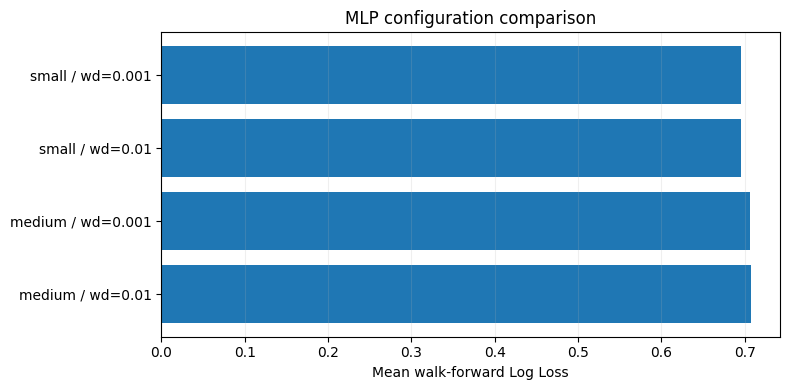

In [2]:
folds = pd.read_csv(REPORT / 'cv_folds_seeds.csv')
summary = pd.read_csv(REPORT / 'cv_summary.csv').sort_values('cv_log_loss')
display(summary)
print('CV fits:', len(folds))
fig, ax = plt.subplots(figsize=(8,4))
labels = summary['architecture'] + ' / wd=' + summary['weight_decay'].astype(str)
ax.barh(labels.iloc[::-1], summary['cv_log_loss'].iloc[::-1])
ax.set(xlabel='Mean walk-forward Log Loss', title='MLP configuration comparison')
ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()

seed,11,42,73
fold,,,
1,0.711274,0.718560,0.712901
2,0.687620,0.699071,0.685404
3,0.672160,0.666444,0.680052
4,0.702677,0.693193,0.718805


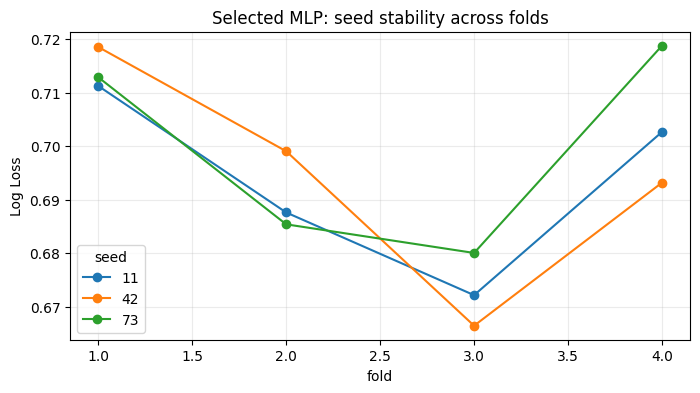

In [3]:
selected = config['selected']
subset = folds.loc[(folds.architecture == selected['architecture']) &
                   (np.isclose(folds.weight_decay, selected['weight_decay']))]
seed_pivot = subset.pivot(index='fold', columns='seed', values='log_loss')
display(seed_pivot)
seed_pivot.plot(marker='o', figsize=(8,4), title='Selected MLP: seed stability across folds')
plt.ylabel('Log Loss')
plt.grid(alpha=.25)
plt.show()

## 2 — Learning curve and generalization gap

The learning curve shows **training** optimization progress; it cannot establish generalization without evaluating held-out dates.

,split,log_loss,brier_score,roc_auc
0,train,0.660639,0.234622,0.627396
1,validation,0.714403,0.256210,0.496893


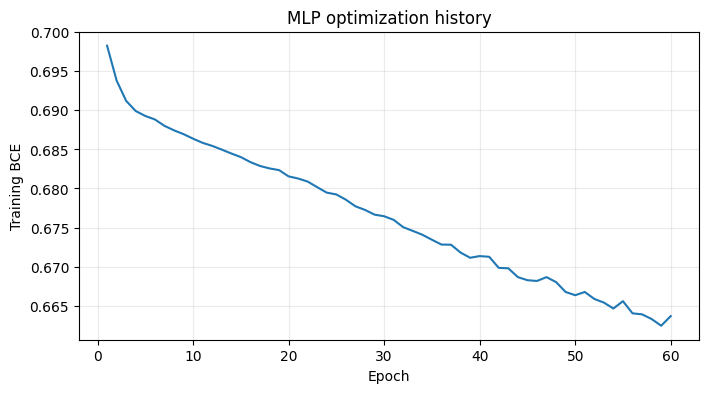

In [4]:
learning = pd.read_csv(REPORT / 'training_losses.csv')
split_metrics = pd.read_csv(REPORT / 'train_vs_validation_metrics.csv')
display(split_metrics[['split','log_loss','brier_score','roc_auc']])
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(learning.epoch, learning.train_loss)
ax.set(xlabel='Epoch', ylabel='Training BCE', title='MLP optimization history')
ax.grid(alpha=.25)
plt.show()

## 3 — Probability forecast comparison

All 4 models predict exactly the same signal dates and binary labels. The table reflects **2019–2021 development validation**, not independent final-test findings.

,model,log_loss,brier_score,roc_auc
0,Constant Probability,0.679269,0.243076,0.500000
1,XGBoost,0.686009,0.246405,0.495446
2,Logistic Regression,0.687180,0.246934,0.486930
3,MLP,0.714403,0.256210,0.496893


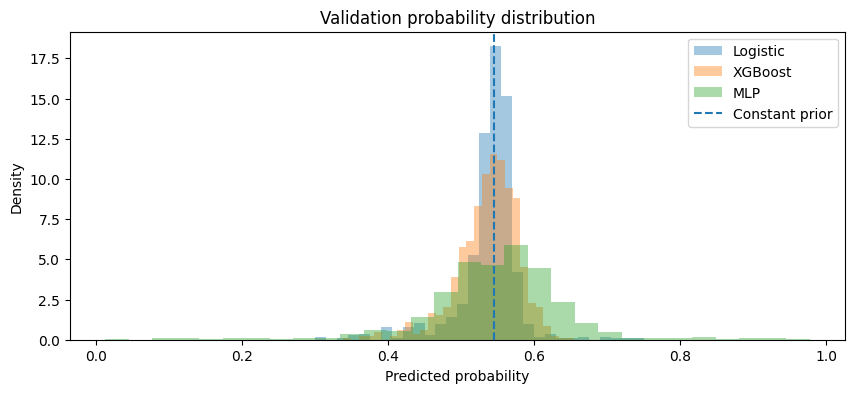

In [5]:
pred = pd.read_csv(REPORT / 'validation_predictions.csv',
                   parse_dates=['signal_date']).set_index('signal_date')
metrics = pd.read_csv(REPORT / 'validation_metrics.csv')
assert pred.index.is_unique and pred.index.is_monotonic_increasing
assert pred.index.max() < pd.Timestamp('2022-01-01')
display(metrics[['model','log_loss','brier_score','roc_auc']].sort_values('log_loss'))
fig, ax = plt.subplots(figsize=(10,4))
for name, col in [('Logistic', 'p_logistic'), ('XGBoost','p_xgboost'), ('MLP','p_mlp')]:
    ax.hist(pred[col], bins=30, alpha=.4, density=True, label=name)
ax.axvline(pred.p_baseline.mean(), ls='--', label='Constant prior')
ax.set(xlabel='Predicted probability', ylabel='Density', title='Validation probability distribution')
ax.legend()
plt.show()

## 4 — Calibration and yearly robustness

Binned calibration curves can be noisy with daily data. Model-dependent predicted probability spreads and return magnitude are distinct from trading profitability.

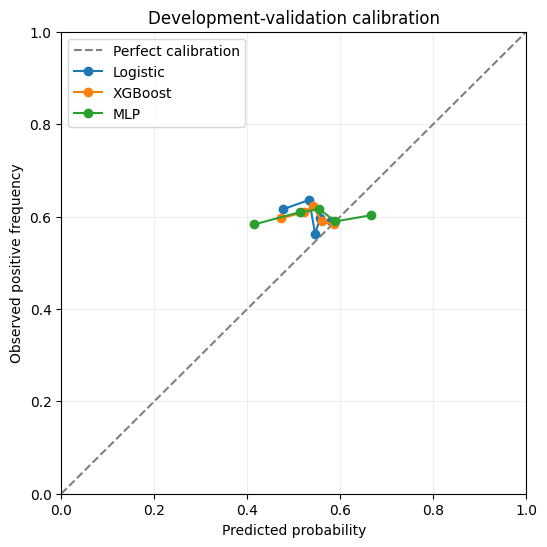

,year,model,n,log_loss
0,2019,Baseline,252,0.679410
1,2019,Logistic,252,0.679086
2,2019,XGBoost,252,0.677786
3,2019,MLP,252,0.702528
4,2020,Baseline,253,0.680539
5,2020,Logistic,253,0.705709
6,2020,XGBoost,253,0.700797
7,2020,MLP,253,0.752713
8,2021,Baseline,250,0.677840
9,2021,Logistic,250,0.676587


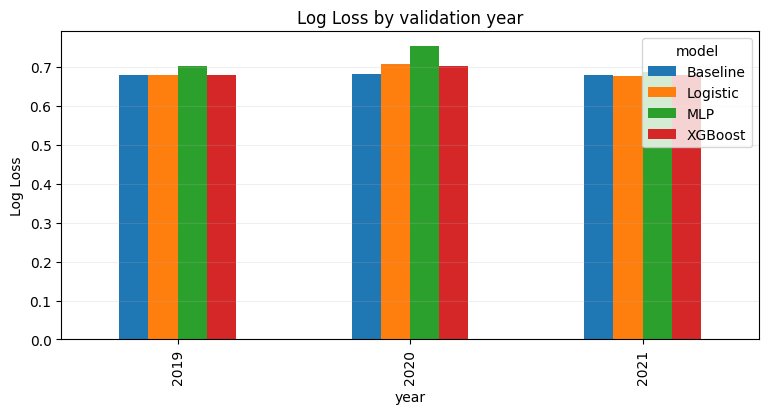

In [6]:
fig, ax = plt.subplots(figsize=(6,6))
ax.plot([0,1],[0,1], ls='--', color='gray', label='Perfect calibration')
for name, col in [('Logistic','p_logistic'),('XGBoost','p_xgboost'),('MLP','p_mlp')]:
    observed, predicted = calibration_curve(pred.actual_label, pred[col], n_bins=5, strategy='quantile')
    ax.plot(predicted, observed, marker='o', label=name)
ax.set(xlim=(0,1), ylim=(0,1), xlabel='Predicted probability',
       ylabel='Observed positive frequency', title='Development-validation calibration')
ax.legend(); ax.grid(alpha=.2)
plt.show()
from sklearn.metrics import log_loss
yearly=[]
for year, sub in pred.groupby(pred.index.year):
    for name, col in [('Baseline','p_baseline'),('Logistic','p_logistic'),('XGBoost','p_xgboost'),('MLP','p_mlp')]:
        yearly.append({'year':year, 'model':name, 'n':len(sub), 'log_loss':log_loss(sub.actual_label,sub[col],labels=[0,1])})
by_year = pd.DataFrame(yearly)
display(by_year)
by_year.pivot(index='year', columns='model', values='log_loss').plot.bar(figsize=(9,4),title='Log Loss by validation year')
plt.ylabel('Log Loss'); plt.grid(axis='y',alpha=.2)
plt.show()

## What does the MLP add?

- **Forecast quality.** The selected 16–8 MLP (weight decay 0.001) has validation Log Loss 0.71440, above logistic regression (0.68718), XGBoost (0.68601) and the prior (0.67927). Validation AUC is 0.497.
- **Seed stability.** For the selected configuration, the largest minus smallest seed loss in folds 1–4 is 0.0073, 0.0137, 0.0136 and 0.0256. These spreads are larger than the 0.00044 difference in average CV loss between the two small-network weight decays. The exact ordering of those two hyperparameters deserves little weight.
- **Calibration.** Across validation quintiles, the lowest 151 forecasts average 41.44% versus 58.28% up days. The highest 151 average 66.56% versus 60.26%. Both extremes stretch farther than the observed frequencies support.
- **Generalization.** Log Loss rises from 0.66064 on training to 0.71440 on validation and AUC falls from 0.627 to 0.497. This is consistent with overfitting. A change in the data distribution across periods could also contribute.